# Task-1

In [ ]:
#Importing Libraries 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error , r2_score 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge , Lasso , ElasticNet , RidgeCV, LassoCV

In [2]:
np.random.seed(42)

# Generate input values
x = np.linspace(0, 2 * np.pi, 30)

# True curve
y_true = np.sin(x)

# Add noise
noise = np.random.normal(0, 0.2, size=len(x))
y = y_true + noise

In [3]:
x_plot = np.linspace(0, 2 * np.pi, 300)
y_true_plot = np.sin(x_plot)

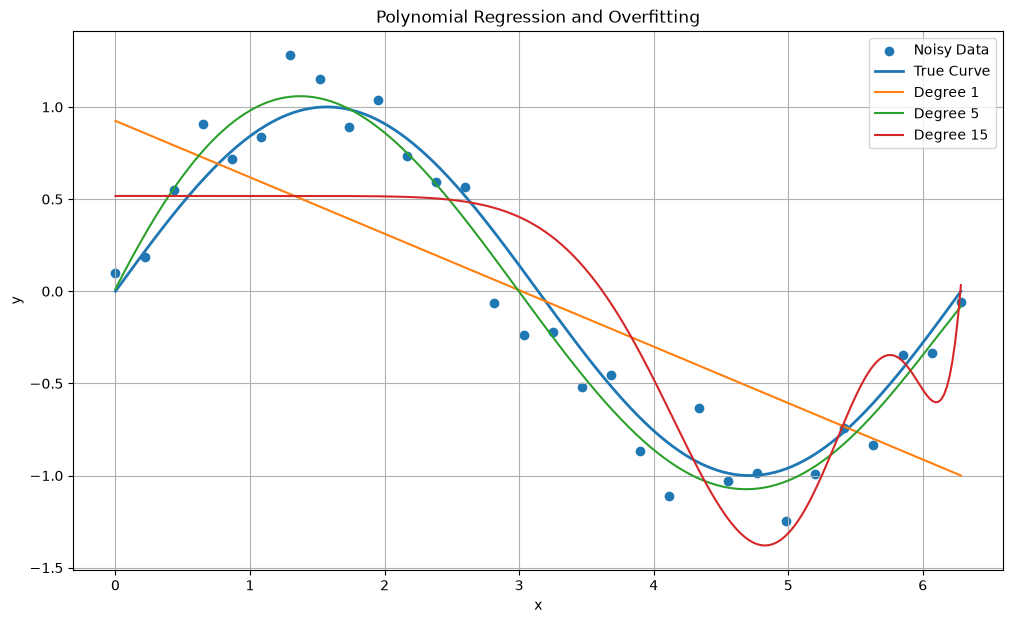

In [4]:
degrees = [1, 5, 15]

results = []

plt.figure(figsize=(12, 7))

# Plot original noisy data
plt.scatter(x, y, label="Noisy Data")

# Plot true curve
plt.plot(x_plot, y_true_plot, label="True Curve", linewidth=2)

for degree in degrees:
    # Create polynomial features
    poly = PolynomialFeatures(degree=degree)

    X_poly = poly.fit_transform(x.reshape(-1, 1))

    # Train model
    model = LinearRegression()
    model.fit(X_poly, y)

    # Predictions on training data
    y_pred = model.predict(X_poly)

    # Training error
    train_error = mean_squared_error(y, y_pred)

    # Predict on smooth x values
    X_plot_poly = poly.transform(x_plot.reshape(-1, 1))
    y_pred_plot = model.predict(X_plot_poly)

    # Error against the true curve
    true_curve_error = mean_squared_error(
        y_true_plot,
        y_pred_plot
    )

    results.append(
        [degree, train_error, true_curve_error]
    )

    # Plot model
    plt.plot(
        x_plot,
        y_pred_plot,
        label=f"Degree {degree}"
    )

plt.xlabel("x")
plt.ylabel("y")
plt.title("Polynomial Regression and Overfitting")
plt.legend()
plt.grid(True)
plt.show()

In [5]:
print("Degree | Training Error | True Curve Error")
print("-" * 45)

for degree, train_error, true_curve_error in results:
    print(
        f"{degree:6} | "
        f"{train_error:.4f}         | "
        f"{true_curve_error:.4f}"
    )

Degree | Training Error | True Curve Error
---------------------------------------------
     1 | 0.2512         | 0.1999
     5 | 0.0225         | 0.0102
    15 | 0.1544         | 0.0966


Degree 1 underfits because a straight line is too simple to capture the sine-wave pattern. Degree 5 gives a good fit because it captures the underlying pattern without following the noise too much. Degree 15 overfits because it is highly flexible and starts learning the noise in the training data. Therefore, a lower training error does not always mean a better model. This is the main idea of overfitting.

# Task-2

In [6]:
# Make results reproducible
np.random.seed(42)

# Create x values
x = np.linspace(0, 2 * np.pi, 30)

# True sine curve
y_true = np.sin(x)

# Add noise
noise = np.random.normal(
    0,
    0.2,
    size=len(x)
)

# Noisy data
y = y_true + noise

In [7]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    x.reshape(-1, 1),
    y,
    test_size=0.2,
    random_state=42
)

In [8]:
# Polynomial degrees from 1 to 15
degrees = range(1, 16)

# Lists to store errors
train_errors = []
test_errors = []

# Try every degree
for degree in degrees:

    # Convert data into polynomial features
    poly = PolynomialFeatures(
        degree=degree
    )

    X_train_poly = poly.fit_transform(
        X_train
    )

    X_test_poly = poly.transform(
        X_test
    )

    # Create Linear Regression model
    model = LinearRegression()

    # Train the model
    model.fit(
        X_train_poly,
        y_train
    )

    # Predict training data
    y_train_pred = model.predict(
        X_train_poly
    )

    # Predict test data
    y_test_pred = model.predict(
        X_test_poly
    )

    # Calculate training error
    train_mse = mean_squared_error(
        y_train,
        y_train_pred
    )

    # Calculate test error
    test_mse = mean_squared_error(
        y_test,
        y_test_pred
    )

    # Save errors
    train_errors.append(
        train_mse
    )

    test_errors.append(
        test_mse
    )

In [9]:
# Find the degree with the lowest test error
best_degree = list(degrees)[
    np.argmin(test_errors)
]

# Get the lowest test error
lowest_test_error = min(
    test_errors
)

print(
    "Best degree:",
    best_degree
)

print(
    "Lowest test error:",
    lowest_test_error
)

Best degree: 3
Lowest test error: 0.02472106609877775


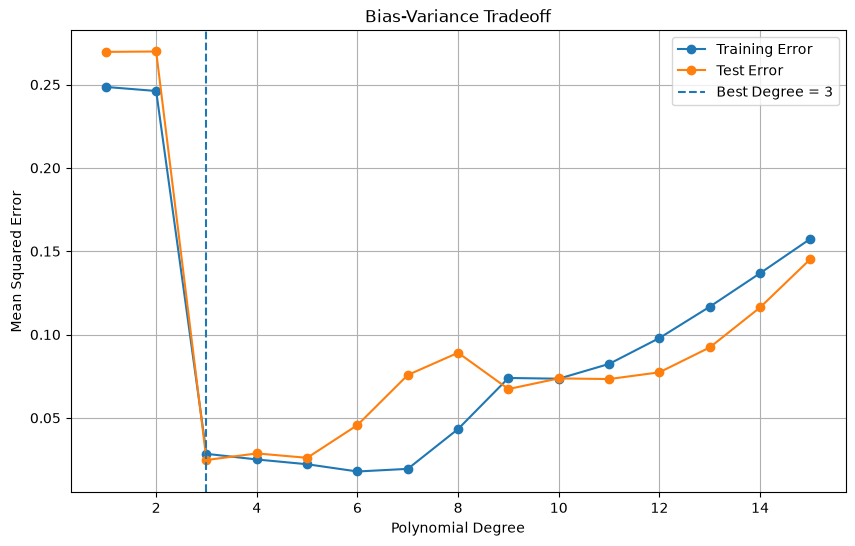

In [10]:
plt.figure(figsize=(10, 6))

# Training error
plt.plot(
    degrees,
    train_errors,
    marker="o",
    label="Training Error"
)

# Test error
plt.plot(
    degrees,
    test_errors,
    marker="o",
    label="Test Error"
)

# Show best degree
plt.axvline(
    best_degree,
    linestyle="--",
    label=f"Best Degree = {best_degree}"
)

plt.xlabel(
    "Polynomial Degree"
)

plt.ylabel(
    "Mean Squared Error"
)

plt.title(
    "Bias-Variance Tradeoff"
)

plt.legend()

plt.grid()

plt.show()

In [11]:
#The best polynomial degree is the degree that gives the lowest test error.

# Task-3

In [12]:
df = pd.read_csv("california_housing.csv")
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"].values
feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X.values, y, test_size=0.2, random_state=42)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print(f"features: {feature_names}")
print(f"training on {len(X_train)}, testing on {len(X_test)} districts")

features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
training on 4000, testing on 1000 districts


In [13]:
# Create Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(
    X_train_s,
    y_train
)

# Predict test data
linear_pred = linear_model.predict(
    X_test_s
)

# Calculate R²
linear_r2 = r2_score(
    y_test,
    linear_pred
)

print(
    "Linear Regression R²:",
    linear_r2
)

Linear Regression R²: 0.8382895198507754


In [14]:
# Create Ridge model
ridge_model = Ridge(
    alpha=1.0
)

# Train the model
ridge_model.fit(
    X_train_s,
    y_train
)

# Predict test data
ridge_pred = ridge_model.predict(
    X_test_s
)

# Calculate R²
ridge_r2 = r2_score(
    y_test,
    ridge_pred
)

print(
    "Ridge R²:",
    ridge_r2
)

Ridge R²: 0.8383112385974028


In [15]:
# Create Lasso model
lasso_model = Lasso(
    alpha=0.01,
    max_iter=10000
)

# Train the model
lasso_model.fit(
    X_train_s,
    y_train
)

# Predict test data
lasso_pred = lasso_model.predict(
    X_test_s
)

# Calculate R²
lasso_r2 = r2_score(
    y_test,
    lasso_pred
)

print(
    "Lasso R²:",
    lasso_r2
)

Lasso R²: 0.838258058780907


In [16]:
# Create Elastic Net model
elastic_model = ElasticNet(
    alpha=0.01,
    l1_ratio=0.5,
    max_iter=10000
)

# Train the model
elastic_model.fit(
    X_train_s,
    y_train
)

# Predict test data
elastic_pred = elastic_model.predict(
    X_test_s
)

# Calculate R²
elastic_r2 = r2_score(
    y_test,
    elastic_pred
)

print(
    "Elastic Net R²:",
    elastic_r2
)

Elastic Net R²: 0.8388158769885453


In [17]:
print("========== MODEL COMPARISON ==========")

print(
    "Linear Regression R²:",
    linear_r2
)

print(
    "Ridge R²:",
    ridge_r2
)

print(
    "Lasso R²:",
    lasso_r2
)

print(
    "Elastic Net R²:",
    elastic_r2
)

========== MODEL COMPARISON ==========
Linear Regression R²: 0.8382895198507754
Ridge R²: 0.8383112385974028
Lasso R²: 0.838258058780907
Elastic Net R²: 0.8388158769885453


In [18]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge",
        "Lasso",
        "Elastic Net"
    ],
    
    "Test R²": [
        linear_r2,
        ridge_r2,
        lasso_r2,
        elastic_r2
    ]
})

results

,Model,Test R²
0,Linear Regression,0.838290
1,Ridge,0.838311
2,Lasso,0.838258
3,Elastic Net,0.838816


In [19]:
print(
    "Linear Regression zero coefficients:",
    np.sum(linear_model.coef_ == 0)
)

print(
    "Ridge zero coefficients:",
    np.sum(ridge_model.coef_ == 0)
)

print(
    "Lasso zero coefficients:",
    np.sum(lasso_model.coef_ == 0)
)

print(
    "Elastic Net zero coefficients:",
    np.sum(elastic_model.coef_ == 0)
)

Linear Regression zero coefficients: 0
Ridge zero coefficients: 0
Lasso zero coefficients: 2
Elastic Net zero coefficients: 2


In [20]:
coefficient_table = pd.DataFrame({
    "Feature": X.columns,
    "Linear": linear_model.coef_,
    "Ridge": ridge_model.coef_,
    "Lasso": lasso_model.coef_,
    "Elastic Net": elastic_model.coef_
})

coefficient_table

,Feature,Linear,Ridge,Lasso,Elastic Net
0,MedInc,0.879916,0.879691,0.868945,0.870029
1,HouseAge,0.169620,0.169570,0.159039,0.163385
2,AveRooms,0.033981,0.033970,0.023783,0.028702
3,AveBedrms,0.001896,0.001897,0.000000,0.000000
4,Population,-0.002174,-0.002178,-0.000000,-0.000000
5,AveOccup,-0.112161,-0.112130,-0.102025,-0.106471
6,Latitude,-0.149141,-0.149095,-0.138933,-0.143159
7,Longitude,-0.170009,-0.169966,-0.160224,-0.164316


# Task-4

In [21]:
# Different regularization strengths
alphas = np.logspace(
    -3,
    0,
    20
)

print(alphas)
# Save feature names
feature_names = X.columns

[0.001      0.00143845 0.00206914 0.00297635 0.00428133 0.00615848
 0.00885867 0.01274275 0.01832981 0.02636651 0.0379269  0.05455595
 0.078476   0.11288379 0.16237767 0.23357215 0.33598183 0.48329302
 0.6951928  1.        ]


In [22]:
for alpha in alphas:

    # Create Lasso model
    lasso = Lasso(
        alpha=alpha,
        max_iter=10000
    )

    # Train model
    lasso.fit(
        X_train_s,
        y_train
    )

    # Find features whose coefficient is exactly zero
    dropped = [
        feature
        for feature, coefficient
        in zip(
            feature_names,
            lasso.coef_
        )
        if coefficient == 0
    ]

    # Find features that still have a coefficient
    remaining = [
        feature
        for feature, coefficient
        in zip(
            feature_names,
            lasso.coef_
        )
        if coefficient != 0
    ]

    print(
        f"\nAlpha = {alpha:.4f}"
    )

    print(
        "Dropped features:",
        dropped
    )

    print(
        "Remaining features:",
        remaining
    )


Alpha = 0.0010
Dropped features: []
Remaining features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Alpha = 0.0014
Dropped features: []
Remaining features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Alpha = 0.0021
Dropped features: ['AveBedrms']
Remaining features: ['MedInc', 'HouseAge', 'AveRooms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Alpha = 0.0030
Dropped features: ['AveBedrms', 'Population']
Remaining features: ['MedInc', 'HouseAge', 'AveRooms', 'AveOccup', 'Latitude', 'Longitude']

Alpha = 0.0043
Dropped features: ['AveBedrms', 'Population']
Remaining features: ['MedInc', 'HouseAge', 'AveRooms', 'AveOccup', 'Latitude', 'Longitude']

Alpha = 0.0062
Dropped features: ['AveBedrms', 'Population']
Remaining features: ['MedInc', 'HouseAge', 'AveRooms', 'AveOccup', 'Latitude', 'Longitude']

Alpha = 0.0089
Dropped features: ['AveBedrms', 'Population']
Remaining 

In [23]:
first_dropped = None

for alpha in alphas:

    lasso = Lasso(
        alpha=alpha,
        max_iter=10000
    )

    lasso.fit(
        X_train_s,
        y_train
    )

    for feature, coefficient in zip(
        feature_names,
        lasso.coef_
    ):

        if coefficient == 0:

            first_dropped = (
                feature,
                alpha
            )

            break

    if first_dropped is not None:
        break


print(
    "First dropped feature:",
    first_dropped[0]
)

print(
    "Alpha:",
    first_dropped[1]
)

First dropped feature: AveBedrms
Alpha: 0.00206913808111479


In [24]:
one_feature_left = None

for alpha in alphas:

    lasso = Lasso(
        alpha=alpha,
        max_iter=10000
    )

    lasso.fit(
        X_train_s,
        y_train
    )

    remaining = [
        feature
        for feature, coefficient
        in zip(
            feature_names,
            lasso.coef_
        )
        if coefficient != 0
    ]

    if len(remaining) == 1:

        one_feature_left = (
            alpha,
            remaining[0]
        )

        break


if one_feature_left is not None:

    print(
        "Alpha when only one feature remains:",
        one_feature_left[0]
    )

    print(
        "Last surviving feature:",
        one_feature_left[1]
    )

else:

    print(
        "No alpha in the selected range left only one feature."
    )

Alpha when only one feature remains: 0.23357214690901212
Last surviving feature: MedInc


Lasso performs feature selection by shrinking some feature coefficients exactly to zero. As the alpha value increases, the regularization becomes stronger and more features are removed from the model. The first dropped feature and the final surviving feature depend on the alpha values and the dataset.


# Task-5

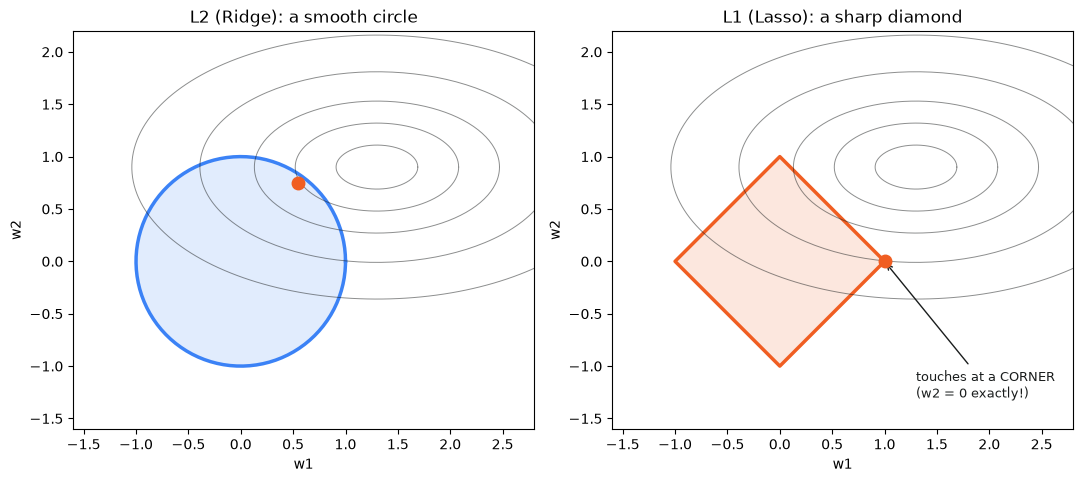

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))

# the constraint region for each penalty, in 2D (two coefficients w1, w2)
theta = np.linspace(0, 2*np.pi, 200)

# L2 (Ridge): a CIRCLE -- sum of squares = constant
ax = axes[0]
circle_x, circle_y = np.cos(theta), np.sin(theta)
ax.plot(circle_x, circle_y, color="#3B82F6", linewidth=2.5)
ax.fill(circle_x, circle_y, color="#3B82F6", alpha=0.15)
# elliptical contours of the loss function, centered off-origin, touching the circle
for r in [0.3, 0.6, 0.9, 1.3, 1.8]:
    ell_x = 1.3 + r*np.cos(theta)*1.3
    ell_y = 0.9 + r*np.sin(theta)*0.7
    ax.plot(ell_x, ell_y, color="#1A1D1D", linewidth=0.7, alpha=0.5)
ax.plot(0.55, 0.75, "o", color="#F05E22", markersize=9, zorder=5)
ax.set_title("L2 (Ridge): a smooth circle")
ax.set_xlim(-1.6, 2.8)
ax.set_ylim(-1.6, 2.2)
ax.set_aspect("equal")
ax.set_xlabel("w1")
ax.set_ylabel("w2")

# L1 (Lasso): a DIAMOND -- sum of absolute values = constant
ax = axes[1]
diamond_x = np.array([1, 0, -1, 0, 1])
diamond_y = np.array([0, 1, 0, -1, 0])
ax.plot(diamond_x, diamond_y, color="#F05E22", linewidth=2.5)
ax.fill(diamond_x, diamond_y, color="#F05E22", alpha=0.15)
for r in [0.3, 0.6, 0.9, 1.3, 1.8]:
    ell_x = 1.3 + r*np.cos(theta)*1.3
    ell_y = 0.9 + r*np.sin(theta)*0.7
    ax.plot(ell_x, ell_y, color="#1A1D1D", linewidth=0.7, alpha=0.5)
ax.plot(1.0, 0.0, "o", color="#F05E22", markersize=9, zorder=5)
ax.annotate("touches at a CORNER\n(w2 = 0 exactly!)", xy=(1.0, 0.0), xytext=(1.3, -1.3),
            fontsize=9, color="#1A1D1D", arrowprops=dict(arrowstyle="->", color="#1A1D1D"))
ax.set_title("L1 (Lasso): a sharp diamond")
ax.set_xlim(-1.6, 2.8)
ax.set_ylim(-1.6, 2.2)
ax.set_aspect("equal")
ax.set_xlabel("w1")
ax.set_ylabel("w2")

plt.tight_layout()
plt.show()

L1 regularization has a diamond-shaped constraint with sharp corners, so during optimization the best solution can land exactly on an axis where one or more coefficients become zero. L2 regularization has a smooth circular boundary without sharp corners, so the solution is usually pulled toward zero but rarely reaches it exactly, meaning its coefficients generally remain small but non-zero.

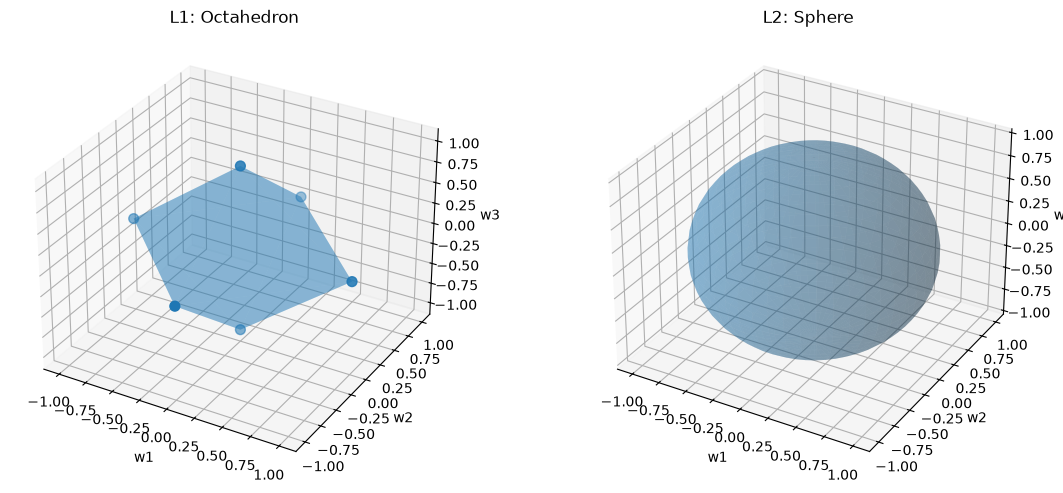

In [26]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

fig = plt.figure(figsize=(12, 5))

# ---------- L1: Octahedron ----------
ax1 = fig.add_subplot(121, projection="3d")

v = np.array([
    [1, 0, 0], [-1, 0, 0],
    [0, 1, 0], [0, -1, 0],
    [0, 0, 1], [0, 0, -1]
])

faces = [
    [0, 2, 4], [0, 4, 3],
    [0, 3, 5], [0, 5, 2],
    [1, 4, 2], [1, 3, 4],
    [1, 5, 3], [1, 2, 5]
]

ax1.add_collection3d(
    Poly3DCollection(
        [[v[i] for i in face] for face in faces],
        alpha=0.3
    )
)

ax1.scatter(v[:, 0], v[:, 1], v[:, 2], s=50)

ax1.set_title("L1: Octahedron")
ax1.set_xlabel("w1")
ax1.set_ylabel("w2")
ax1.set_zlabel("w3")

# ---------- L2: Sphere ----------
ax2 = fig.add_subplot(122, projection="3d")

u = np.linspace(0, 2 * np.pi, 50)
v_angle = np.linspace(0, np.pi, 30)

x = np.outer(np.cos(u), np.sin(v_angle))
y = np.outer(np.sin(u), np.sin(v_angle))
z = np.outer(np.ones_like(u), np.cos(v_angle))

ax2.plot_surface(x, y, z, alpha=0.3)

ax2.set_title("L2: Sphere")
ax2.set_xlabel("w1")
ax2.set_ylabel("w2")
ax2.set_zlabel("w3")

plt.tight_layout()
plt.show()

In [27]:
#l2 has 6 and l1 has 0.

# Task-6

In [28]:
#Plot the full coefficient path (coefficient value vs alpha) for both Ridge and Lasso on your California housing features

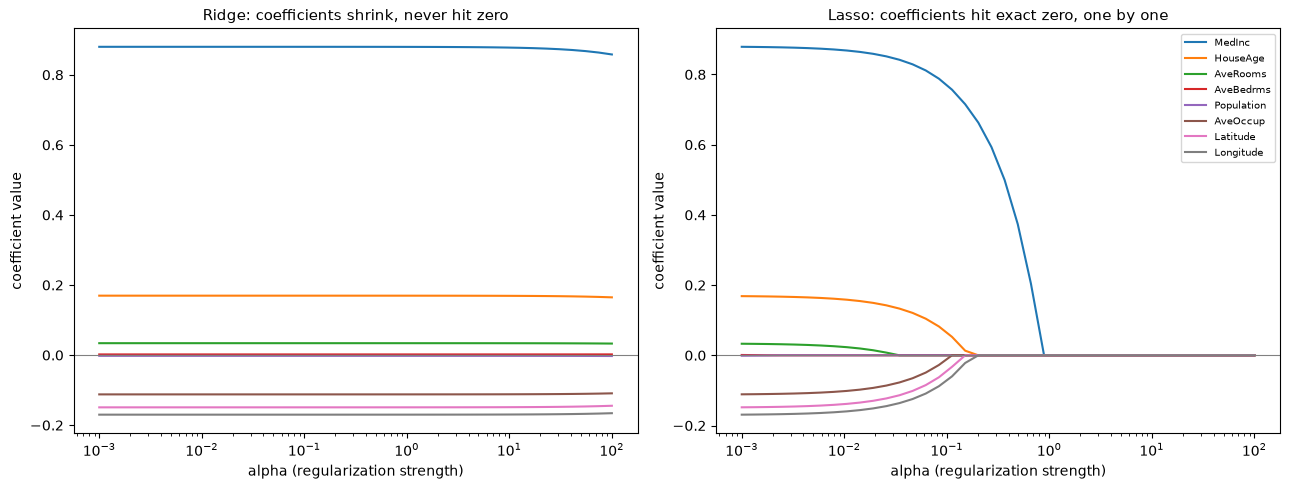

In [ ]:
alphas = np.logspace(-3, 2, 40)
ridge_coef_path = np.array([Ridge(alpha=a).fit(X_train_s, y_train).coef_ for a in alphas])
lasso_coef_path = np.array([Lasso(alpha=a, max_iter=5000).fit(X_train_s, y_train).coef_ for a in alphas])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for i, name in enumerate(feature_names):
    axes[0].plot(alphas, ridge_coef_path[:, i], label=name)
    axes[1].plot(alphas, lasso_coef_path[:, i], label=name)

for ax, title in zip(axes, ["Ridge: coefficients shrink, never hit zero", "Lasso: coefficients hit exact zero, one by one"]):
    ax.set_xscale("log")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_xlabel("alpha (regularization strength)")
    ax.set_ylabel("coefficient value")
    ax.set_title(title, fontsize=10.5)

axes[1].legend(fontsize=7.5, loc="upper right")
plt.tight_layout()
plt.show()

In [30]:
# Use RidgeCV and LassoCV to automatically select the best alpha for each.
ridge_cv = RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5).fit(X_train_s, y_train)
lasso_cv = LassoCV(alphas=np.logspace(-3, 1, 50), cv=5, max_iter=5000).fit(X_train_s, y_train)

print(f"RidgeCV chose alpha = {ridge_cv.alpha_:.4f}")
print(f"  test R2: {r2_score(y_test, ridge_cv.predict(X_test_s)):.4f}")

print(f"\nLassoCV chose alpha = {lasso_cv.alpha_:.4f}")
print(f"  test R2: {r2_score(y_test, lasso_cv.predict(X_test_s)):.4f}")
print(f"  features kept: {(lasso_cv.coef_ != 0).sum()}/{len(lasso_cv.coef_)}")
print(f"  dropped: {[f for f, c in zip(feature_names, lasso_cv.coef_) if c == 0]}")

RidgeCV chose alpha = 3.5565
  test R2: 0.8384

LassoCV chose alpha = 0.0026
  test R2: 0.8385
  features kept: 6/8
  dropped: ['AveBedrms', 'Population']


In [31]:
#Compare the CV-selected alphas' test R2 against your best hand-picked alpha from Task 3 — how close are they?

Best hand-picked:

RidgeCV: alpha = 3.5565 → Test R² = 0.8384

LassoCV: alpha = 0.0026 → Test R² = 0.8385

Conclusion: CV-selected models are very close and slightly better than the best hand-picked result.

In [32]:
#Write two sentences on why tuning via cross-validation on the TRAINING set is more trustworthy than tuning by eye on the test set.

In [33]:
# Because it checks the multiple values for the model then finds out which one is the best for the model where the least error is there 
# by cross validation it validate all data into multiple parts 